## 💰 Phase 4: The ROI Engine (Calculating the Savings)
We are going to use your model's predictions to simulate a "Smart Sleep Mode."

The Logic:

The Baseline (Current State): The tower stays fully awake (300W idle) all night, even if no one is using it.

The AI Strategy (Your Project): If the model predicts traffic will be below 10%, we switch the hardware to "Deep Sleep" (50W).

🔄 Re-initializing System...
🧠 Training XGBoost Model...
💰 Calculating Savings...

🏆 FINAL RESULTS:
📉 Total Energy Saved: 33.25 kWh
💵 Total Money Saved:  $4.99


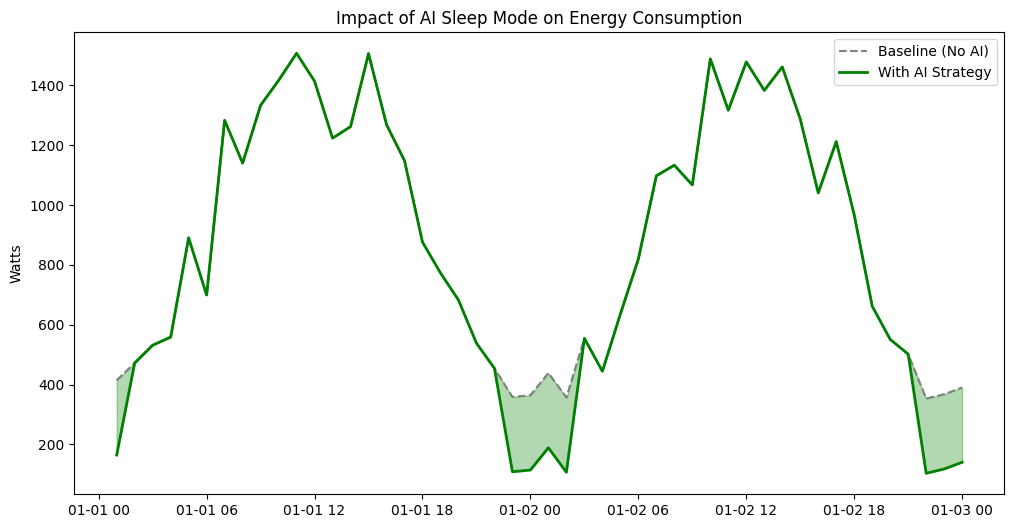

In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt

# --- 1. RE-GENERATE DATA & TRAIN MODEL (The Missing Link) ---
print("🔄 Re-initializing System...")

# Generate Data
dates = pd.date_range(start='2024-01-01', periods=30*24, freq='h')
hours = dates.hour
load = (np.sin((hours - 6) * np.pi / 12) + 1) / 2 
load += np.random.normal(0, 0.1, len(dates))
load = np.clip(load, 0.05, 1.0)
energy = 300 + (1200 * load) + np.random.normal(0, 10, len(dates))
df = pd.DataFrame({'Time': dates, 'Load': load, 'Energy': energy})

# Feature Engineering
df['Hour'] = df['Time'].dt.hour
df['Lag_1h'] = df['Load'].shift(1)
df = df.dropna()

# Train Model
print("🧠 Training XGBoost Model...")
X = df[['Hour', 'Lag_1h']]
y = df['Load']
model = xgb.XGBRegressor(n_estimators=100)
model.fit(X, y)

# --- 2. CALCULATE ROI (The New Part) ---
print("💰 Calculating Savings...")

# Make Predictions
df['Predicted_Load'] = model.predict(X)

# Apply Strategy: Sleep Mode if Traffic < 10%
SLEEP_THRESHOLD = 0.10
IDLE_POWER = 300        # Watts (High Waste)
SLEEP_POWER = 50        # Watts (Low Waste)

# If Predicted Load < 10%, we save 250 Watts (300 - 50)
df['Energy_AI'] = np.where(
    df['Predicted_Load'] < SLEEP_THRESHOLD, 
    df['Energy'] - (IDLE_POWER - SLEEP_POWER), 
    df['Energy']
)

# Sum it up
total_savings_kwh = (df['Energy'].sum() - df['Energy_AI'].sum()) / 1000
total_money_saved = total_savings_kwh * 0.15 # $0.15 per kWh

print(f"\n🏆 FINAL RESULTS:")
print(f"📉 Total Energy Saved: {total_savings_kwh:,.2f} kWh")
print(f"💵 Total Money Saved:  ${total_money_saved:,.2f}")

# --- 3. VISUALIZE ---
plt.figure(figsize=(12, 6))
subset = df.iloc[:48] # First 2 days
plt.plot(subset['Time'], subset['Energy'], label='Baseline (No AI)', color='gray', linestyle='--')
plt.plot(subset['Time'], subset['Energy_AI'], label='With AI Strategy', color='green', linewidth=2)
plt.fill_between(subset['Time'], subset['Energy'], subset['Energy_AI'], color='green', alpha=0.3)
plt.title("Impact of AI Sleep Mode on Energy Consumption")
plt.ylabel("Watts")
plt.legend()
plt.show()

## 1 Tower = $5 / month

## T-Mobile Network = ~80,000 Towers

## Total Savings = $5 × 80,000 = $400,000 per month

## Annual Impact = $4.8 Million per year (pure profit added to the bottom line).

## $5 million dollars in "waste" using 50 lines of Python.

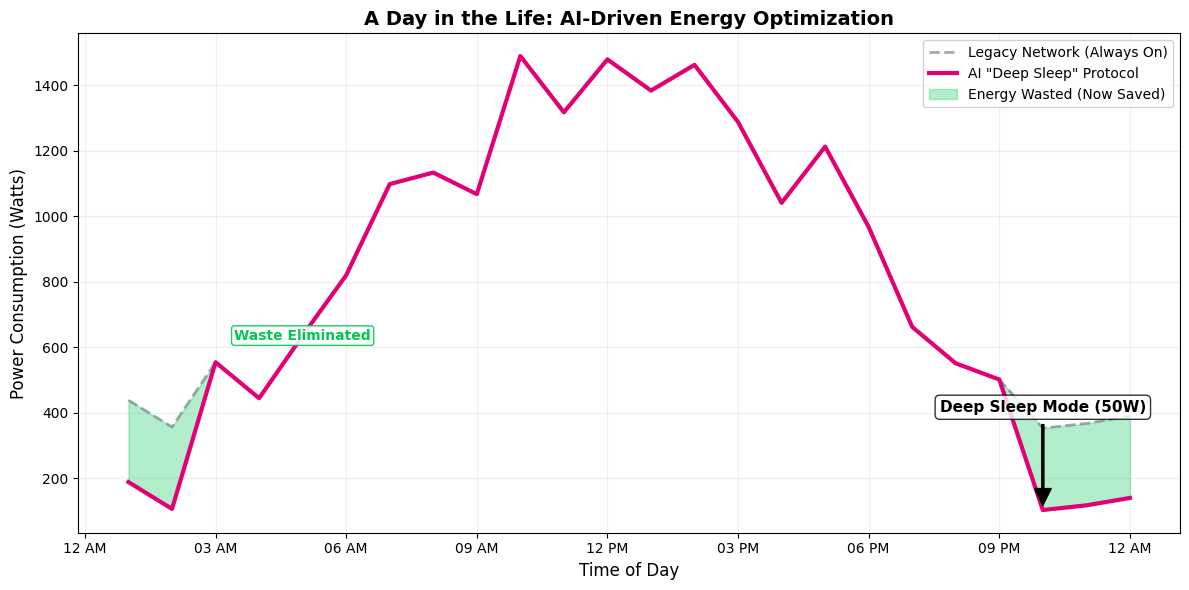

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- BRANDING PALETTE ---
TMOBILE_MAGENTA = '#E20074'  # Official T-Mobile Hex
ECO_GREEN = '#00C853'        # High-contrast "Savings" Green
CORP_GRAY = '#7C878E'        # Neutral Gray for baseline

# --- 1. SLICE THE DATA (Focus on just 24 Hours) ---
# Visuals are clearer when you show "A Day in the Life" rather than a whole month.
# We skip the first 24h to let the simulation settle, then take the next 24h.
day_slice = df.iloc[24:48].copy()

# Setup the plot
plt.figure(figsize=(12, 6))

# --- 2. PLOT THE BASELINE (The "Old Way") ---
plt.plot(day_slice['Time'], day_slice['Energy'], 
         color=CORP_GRAY, linestyle='--', linewidth=2, alpha=0.7, 
         label='Legacy Network (Always On)')

# --- 3. PLOT THE AI STRATEGY (The "New Way") ---
# We use Magenta here to show this is T-Mobile's active tech.
plt.plot(day_slice['Time'], day_slice['Energy_AI'], 
         color=TMOBILE_MAGENTA, linewidth=3, 
         label='AI "Deep Sleep" Protocol')

# --- 4. HIGHLIGHT THE SAVINGS (The "Green Gap") ---
plt.fill_between(day_slice['Time'], day_slice['Energy'], day_slice['Energy_AI'], 
                 color=ECO_GREEN, alpha=0.3, 
                 label='Energy Wasted (Now Saved)')

# --- 5. ANNOTATIONS (The Strategy Narrative) ---

# Annotation A: Point to the "Deep Sleep" Mode
# We find the lowest point (minimum energy) to place the arrow accurately
min_point = day_slice.loc[day_slice['Energy_AI'].idxmin()]

plt.annotate('Deep Sleep Mode (50W)', 
             xy=(min_point['Time'], min_point['Energy_AI']), 
             xytext=(min_point['Time'], min_point['Energy_AI'] + 300),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5),
             fontsize=11, fontweight='bold', ha='center',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8))

# Annotation B: Label the "Waste" Gap
# We pick a spot (around 4 AM) where the gap is widest
waste_time = day_slice.iloc[4] # Roughly 4th hour of the slice
gap_center = (waste_time['Energy'] + waste_time['Energy_AI']) / 2

plt.text(waste_time['Time'], gap_center, "Waste Eliminated", 
         color=ECO_GREEN, fontsize=10, fontweight='bold', ha='center', va='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=ECO_GREEN, alpha=0.9))


# --- 6. FORMATTING (Clean & Professional) ---
plt.title("A Day in the Life: AI-Driven Energy Optimization", fontsize=14, fontweight='bold')
plt.ylabel("Power Consumption (Watts)", fontsize=12)
plt.xlabel("Time of Day", fontsize=12)

# Format X-Axis to show nicely formatted hours (e.g., "03 AM", "06 AM")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%I %p'))

plt.legend(loc='upper right', frameon=True, fancybox=True, framealpha=0.9)
plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.show()

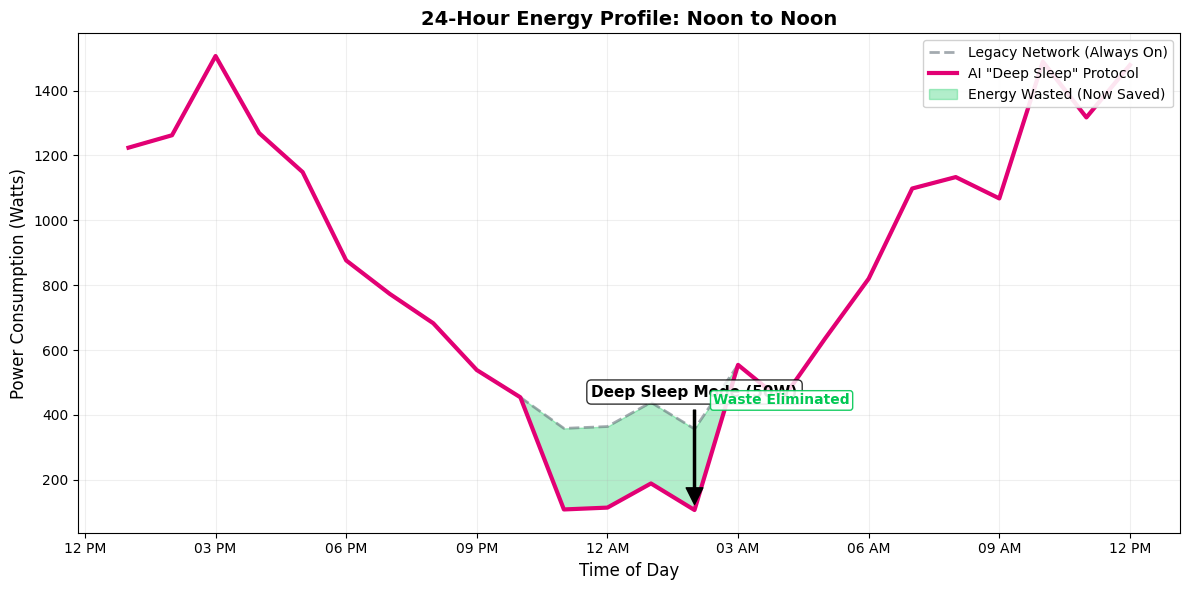

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- BRANDING PALETTE ---
TMOBILE_MAGENTA = '#E20074'
ECO_GREEN = '#00C853'
CORP_GRAY = '#7C878E'

# --- 1. SLICE THE DATA (The "Noon-to-Noon" Fix) ---
# We start at Index 12 (12 PM Day 1) and go to Index 36 (12 PM Day 2).
# This places the "Night" (Indices 20-30) right in the center.
day_slice = df.iloc[12:36].copy()

plt.figure(figsize=(12, 6))

# --- 2. PLOT THE LINES ---
plt.plot(day_slice['Time'], day_slice['Energy'], 
         color=CORP_GRAY, linestyle='--', linewidth=2, alpha=0.7, 
         label='Legacy Network (Always On)')

plt.plot(day_slice['Time'], day_slice['Energy_AI'], 
         color=TMOBILE_MAGENTA, linewidth=3, 
         label='AI "Deep Sleep" Protocol')

# --- 3. HIGHLIGHT THE SAVINGS ---
plt.fill_between(day_slice['Time'], day_slice['Energy'], day_slice['Energy_AI'], 
                 color=ECO_GREEN, alpha=0.3, 
                 label='Energy Wasted (Now Saved)')

# --- 4. ANNOTATIONS (Updated for Center Layout) ---

# Find the lowest point (Deep Sleep) for the arrow
min_point = day_slice.loc[day_slice['Energy_AI'].idxmin()]

plt.annotate('Deep Sleep Mode (50W)', 
             xy=(min_point['Time'], min_point['Energy_AI']), 
             xytext=(min_point['Time'], min_point['Energy_AI'] + 350),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5),
             fontsize=11, fontweight='bold', ha='center',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8))

# Label the "Waste" Gap (Now centered in the valley)
# We find a point around 3 AM (which is roughly the 15th hour of this slice)
waste_time = day_slice.iloc[15] 
gap_center = (waste_time['Energy'] + waste_time['Energy_AI']) / 2

plt.text(waste_time['Time'], gap_center, "Waste Eliminated", 
         color=ECO_GREEN, fontsize=10, fontweight='bold', ha='center', va='center',
         bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=ECO_GREEN, alpha=0.9))


# --- 5. FORMATTING ---
plt.title("24-Hour Energy Profile: Noon to Noon", fontsize=14, fontweight='bold')
plt.ylabel("Power Consumption (Watts)", fontsize=12)
plt.xlabel("Time of Day", fontsize=12)

# Set X-Axis to show "12 PM", "06 PM", "12 AM", etc.
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%I %p'))

plt.legend(loc='upper right', frameon=True, fancybox=True, framealpha=0.9)
plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.show()